In [1]:
# ==========================================
# Cell 0: Import Libraries
# ==========================================

import os
import sys
import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Tuple, List, Optional, Dict

# Set random seed for reproducibility
np.random.seed(42)

print('OpenCV Version:', cv2.__version__)
print('NumPy Version :', np.__version__)

OpenCV Version: 5.1.0
NumPy Version : 2.5.5


Loaded Sample: ck2bxiswtxuw80838qkisqjwz.jpg
Image Shape  : (520, 621, 3)
Mask Shape   : (520, 621) (Polyp Pixels: 142856)

Histogram Statistics:
  mean           : 96.20
  std            : 67.10
  min            : 0.00
  max            : 255.00
  dynamic_range  : 255.00
  entropy        : 6.91


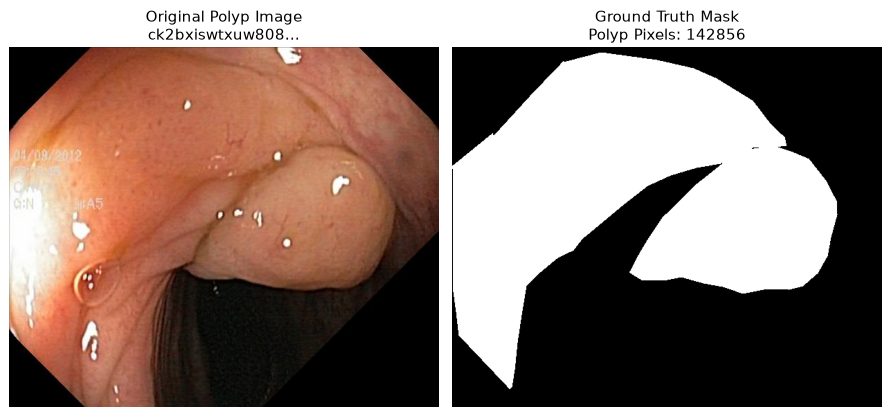

In [2]:
# ==========================================
# Cell 1: Load Dataset Sample (ck2bxiswtxuw80838qkisqjwz.jpg)
# ==========================================

CANDIDATE_DATASET_PATHS = [
    Path("../data/dataset.zip"),
    Path("../data/kvasir-seg.zip"),
    Path("data/dataset.zip"),
    Path("data/kvasir-seg.zip"),
    Path(r"c:\Users\ohmar\OneDrive\Desktop\kvasir-seg.zip"),
    Path.home() / "Desktop" / "kvasir-seg.zip",
    Path("kvasir-seg.zip"),
    Path("dataset.zip")
]

def get_dataset_path() -> Optional[Path]:
    for candidate in CANDIDATE_DATASET_PATHS:
        if candidate.is_file():
            return candidate
    return None

def load_dataset_sample(sample_index: int = 0) -> Tuple[np.ndarray, np.ndarray, str]:
    zip_path = get_dataset_path()
    if zip_path is None:
        raise FileNotFoundError("Dataset zip archive not found.")
        
    with zipfile.ZipFile(zip_path, "r") as archive:
        all_files = archive.namelist()
        image_extensions = (".jpg", ".jpeg", ".png", ".bmp")
        image_files = []
        mask_map = {}
        
        for file in all_files:
            if file.lower().endswith(image_extensions):
                if "/masks/" in file.lower() or file.lower().startswith("masks/"):
                    mask_map[Path(file).stem] = file
                elif "/images/" in file.lower() or file.lower().startswith("images/"):
                    image_files.append(file)
                    
        sample_img_file = image_files[sample_index % len(image_files)]
        sample_name = Path(sample_img_file).stem
        sample_mask_file = mask_map[sample_name]
        
        img_bytes = archive.read(sample_img_file)
        image = cv2.imdecode(np.frombuffer(img_bytes, dtype=np.uint8), cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        mask_bytes = archive.read(sample_mask_file)
        mask = cv2.imdecode(np.frombuffer(mask_bytes, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
        mask_binary = (mask > 127).astype(np.uint8)
        
        return image, mask_binary, sample_name

def analyze_histogram_stats(img: np.ndarray) -> Dict[str, float]:
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img
    hist, _ = np.histogram(gray, bins=256, range=(0, 256), density=True)
    hist = hist[hist > 0]
    entropy = float(-np.sum(hist * np.log2(hist)))
    return {
        "mean": float(np.mean(gray)),
        "std": float(np.std(gray)),
        "min": float(np.min(gray)),
        "max": float(np.max(gray)),
        "dynamic_range": float(np.max(gray) - np.min(gray)),
        "entropy": entropy
    }

image, mask, sample_name = load_dataset_sample(sample_index=0)
print(f"Loaded Sample: {sample_name}.jpg")
print(f"Image Shape  : {image.shape}")
print(f"Mask Shape   : {mask.shape} (Polyp Pixels: {mask.sum()})")

stats = analyze_histogram_stats(image)
print("\nHistogram Statistics:")
for k, v in stats.items():
    print(f"  {k:<15}: {v:.2f}")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title(f"Original Polyp Image\n{sample_name[:15]}...")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title(f"Ground Truth Mask\nPolyp Pixels: {mask.sum()}")
plt.axis("off")

plt.tight_layout()
plt.show()

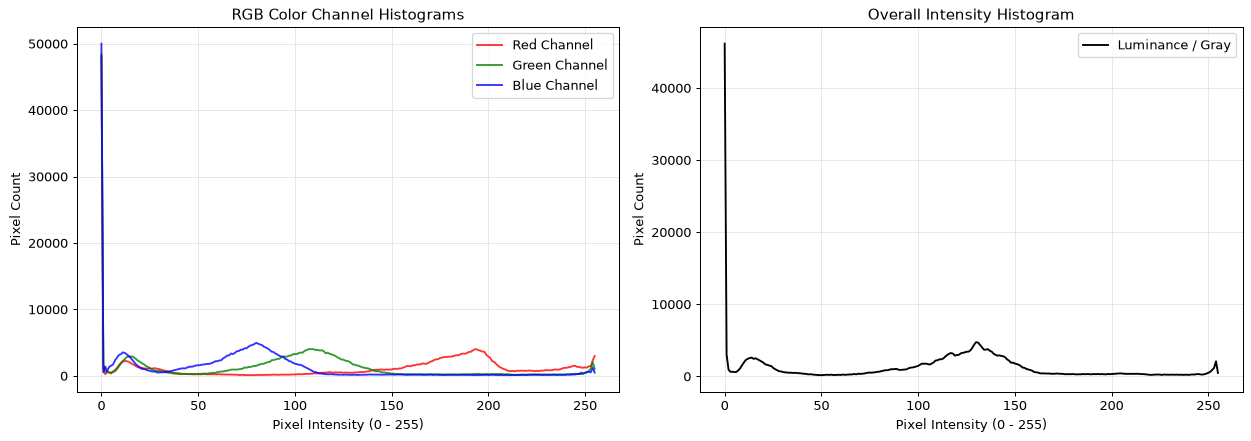

In [3]:
# ==========================================
# Cell 2: Histogram Analysis (RGB Channels & Grayscale)
# ==========================================

def compute_histogram(img: np.ndarray) -> Dict[str, np.ndarray]:
    histograms = {}
    colors = ("red", "green", "blue")
    for i, color in enumerate(colors):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        histograms[color] = hist.flatten()
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    hist_gray = cv2.calcHist([gray], [0], None, [256], [0, 256])
    histograms["intensity"] = hist_gray.flatten()
    return histograms

histograms = compute_histogram(image)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(histograms["red"], color="red", label="Red Channel", alpha=0.8)
plt.plot(histograms["green"], color="green", label="Green Channel", alpha=0.8)
plt.plot(histograms["blue"], color="blue", label="Blue Channel", alpha=0.8)
plt.title("RGB Color Channel Histograms")
plt.xlabel("Pixel Intensity (0 - 255)")
plt.ylabel("Pixel Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(histograms["intensity"], color="black", label="Luminance / Gray", lw=1.5)
plt.title("Overall Intensity Histogram")
plt.xlabel("Pixel Intensity (0 - 255)")
plt.ylabel("Pixel Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

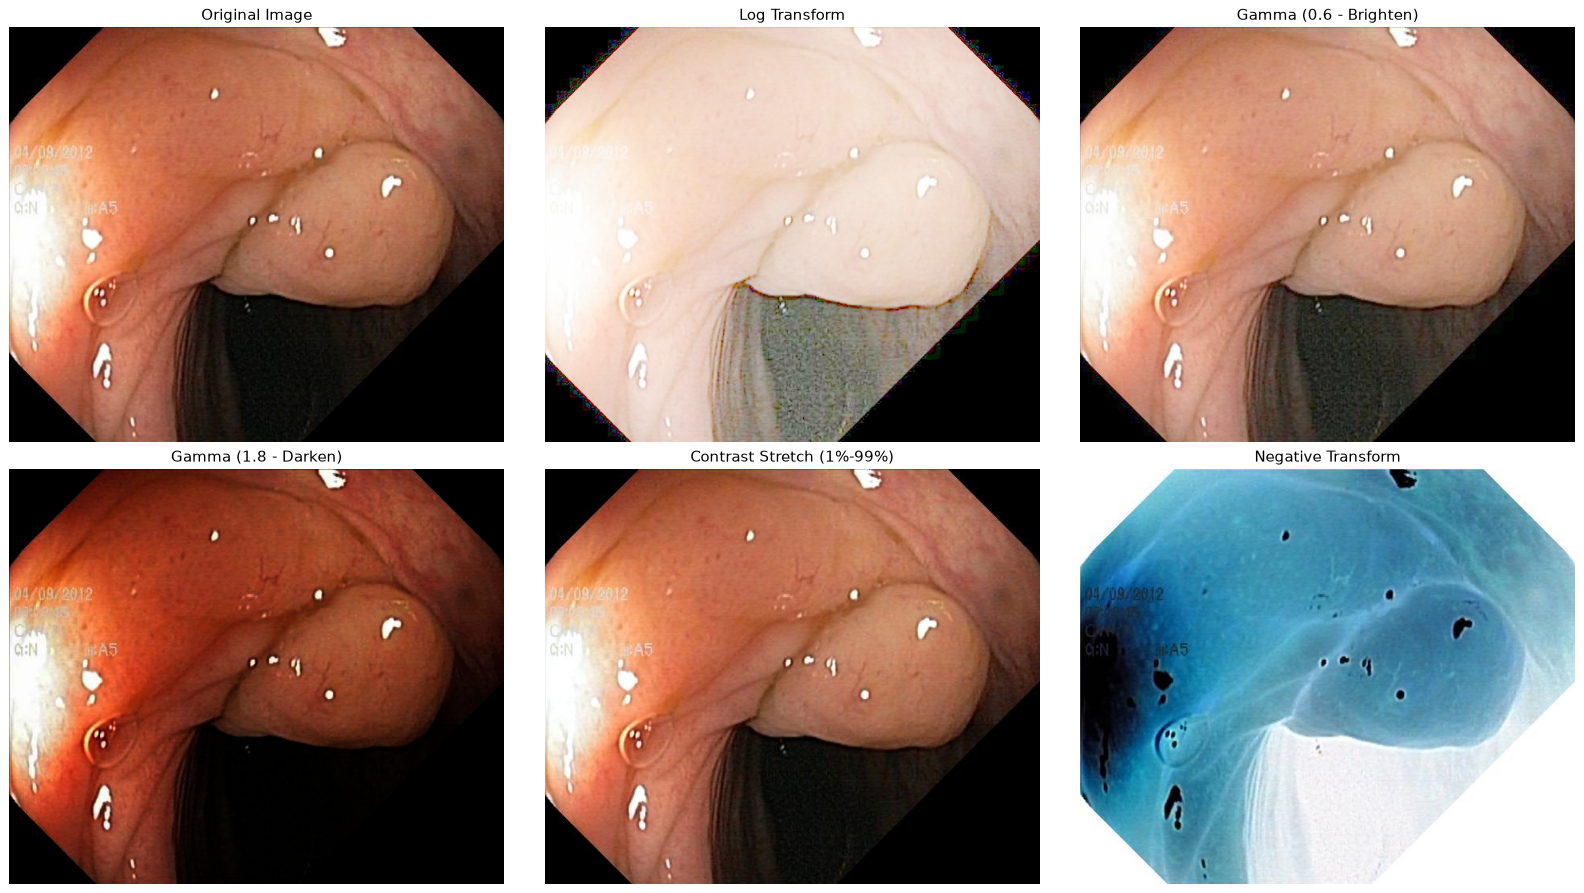

In [4]:
# ==========================================
# Cell 3: Point Transformations (Log, Gamma, Contrast Stretching, Negative)
# ==========================================

def log_transform(img: np.ndarray) -> np.ndarray:
    img_float = img.astype(np.float64)
    c = 255.0 / np.log(1.0 + np.max(img_float))
    return np.clip(c * np.log(1.0 + img_float), 0, 255).astype(np.uint8)

def power_law_transform(img: np.ndarray, gamma: float = 1.0) -> np.ndarray:
    norm = img.astype(np.float64) / 255.0
    return np.clip((norm ** gamma) * 255.0, 0, 255).astype(np.uint8)

def contrast_stretching(img: np.ndarray, p_low: float = 1.0, p_high: float = 99.0) -> np.ndarray:
    img_float = img.astype(np.float64)
    stretched = np.zeros_like(img_float)
    for ch in range(3):
        r_min = np.percentile(img_float[..., ch], p_low)
        r_max = np.percentile(img_float[..., ch], p_high)
        if r_max > r_min:
            stretched[..., ch] = (img_float[..., ch] - r_min) * (255.0 / (r_max - r_min))
        else:
            stretched[..., ch] = img_float[..., ch]
    return np.clip(stretched, 0, 255).astype(np.uint8)

def image_negative(img: np.ndarray) -> np.ndarray:
    return 255 - img

img_log = log_transform(image)
img_gamma_low = power_law_transform(image, gamma=0.6)
img_gamma_high = power_law_transform(image, gamma=1.8)
img_contrast = contrast_stretching(image)
img_neg = image_negative(image)

point_transforms = [
    ("Original Image", image),
    ("Log Transform", img_log),
    ("Gamma (0.6 - Brighten)", img_gamma_low),
    ("Gamma (1.8 - Darken)", img_gamma_high),
    ("Contrast Stretch (1%-99%)", img_contrast),
    ("Negative Transform", img_neg)
]

plt.figure(figsize=(18, 10))
for i, (title, img_t) in enumerate(point_transforms):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img_t)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

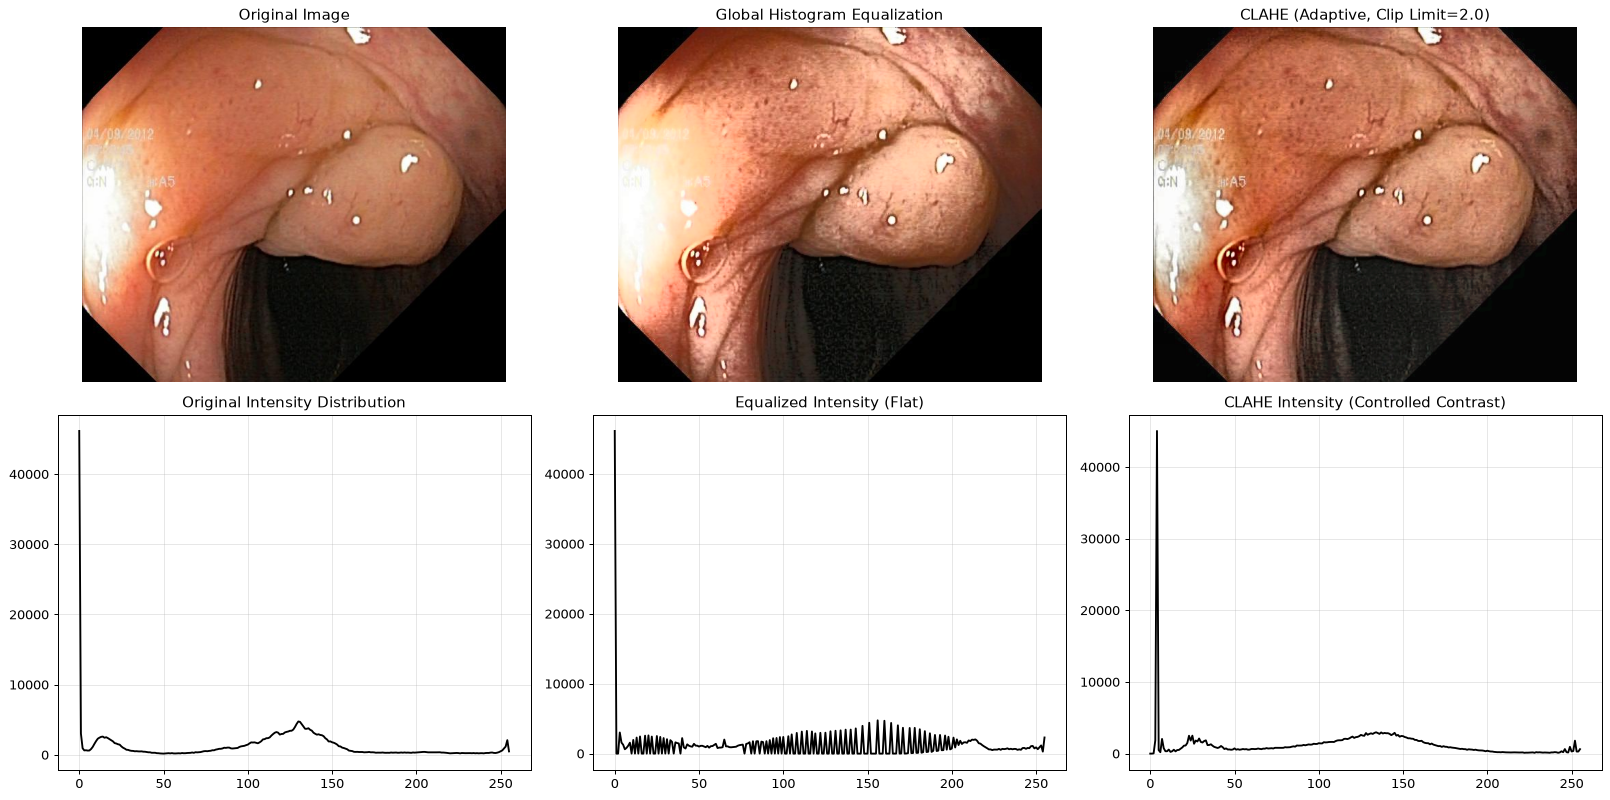

In [5]:
# ==========================================
# Cell 4: Histogram Equalization (Global HE vs CLAHE)
# ==========================================

def histogram_equalization(img: np.ndarray) -> np.ndarray:
    ycrcb = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycrcb[..., 0] = cv2.equalizeHist(ycrcb[..., 0])
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)

def apply_clahe(img: np.ndarray, clip_limit: float = 2.0) -> np.ndarray:
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8))
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

he_img = histogram_equalization(image)
clahe_img = apply_clahe(image, clip_limit=2.0)

he_hist = compute_histogram(he_img)["intensity"]
clahe_hist = compute_histogram(clahe_img)["intensity"]

plt.figure(figsize=(18, 9))
plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(he_img)
plt.title("Global Histogram Equalization")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(clahe_img)
plt.title("CLAHE (Adaptive, Clip Limit=2.0)")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.plot(histograms["intensity"], color="black")
plt.title("Original Intensity Distribution")
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 5)
plt.plot(he_hist, color="black")
plt.title("Equalized Intensity (Flat)")
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 6)
plt.plot(clahe_hist, color="black")
plt.title("CLAHE Intensity (Controlled Contrast)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

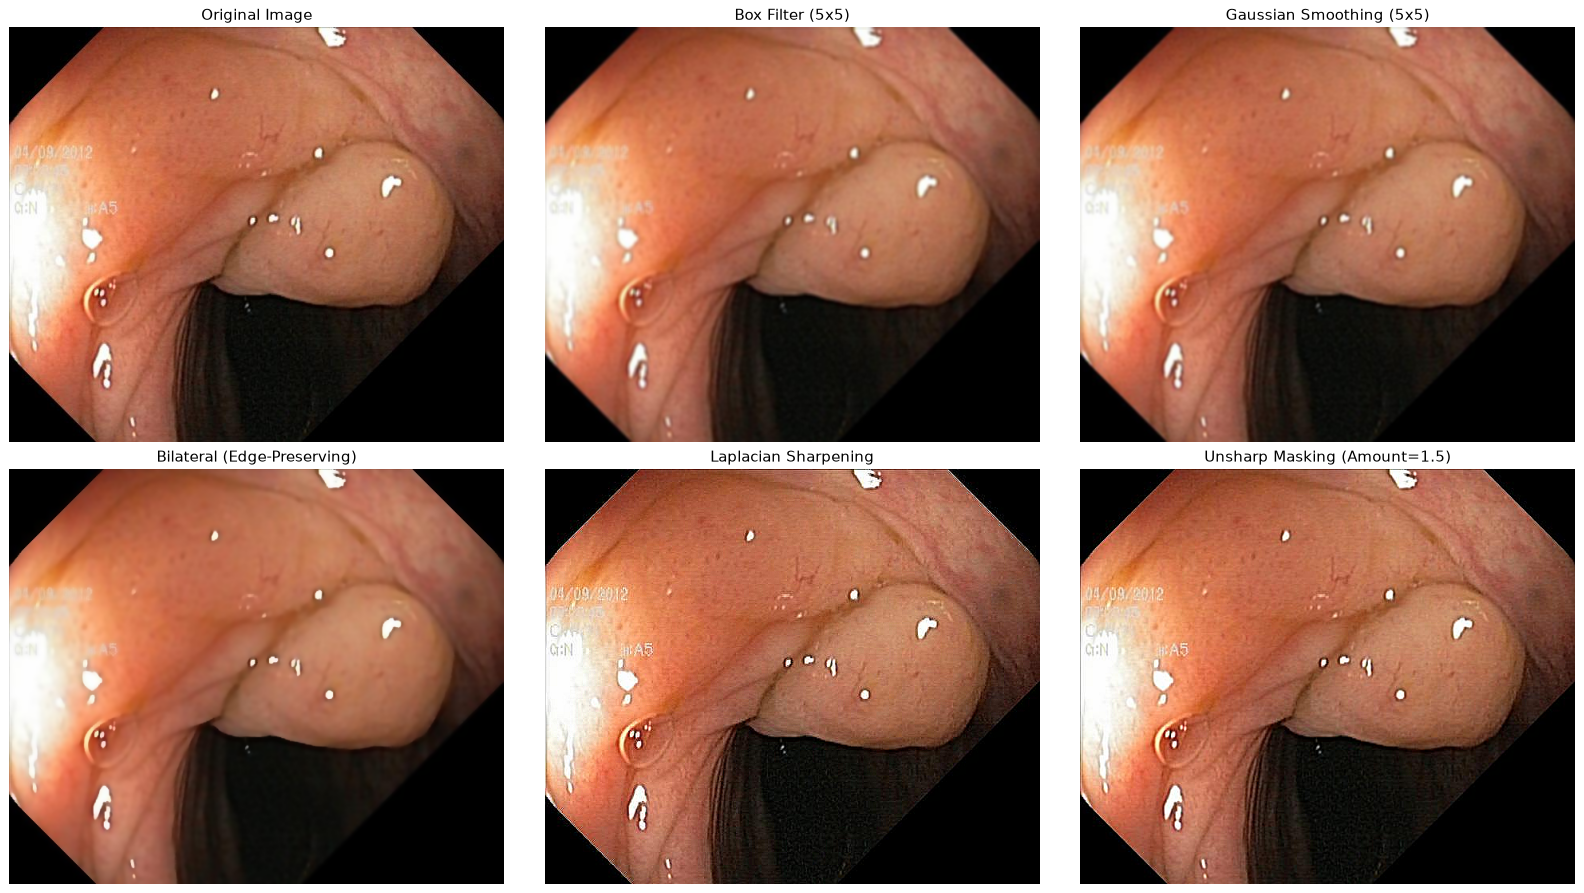

In [6]:
# ==========================================
# Cell 5: Smoothing and Sharpening Spatial Filters
# ==========================================

def apply_box_filter(img: np.ndarray, k: int = 5) -> np.ndarray:
    return cv2.blur(img, (k, k))

def apply_gaussian_smoothing(img: np.ndarray, k: int = 5, sigma: float = 1.5) -> np.ndarray:
    if k % 2 == 0:
        k += 1
    return cv2.GaussianBlur(img, (k, k), sigma)

def apply_bilateral_smoothing(img: np.ndarray, d: int = 9, s_color: float = 75.0, s_space: float = 75.0) -> np.ndarray:
    return cv2.bilateralFilter(img, d, s_color, s_space)

def apply_laplacian_sharpening(img: np.ndarray, c: float = 1.0) -> np.ndarray:
    kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], dtype=np.float64)
    img_f = img.astype(np.float64)
    sharp = np.zeros_like(img_f)
    for ch in range(3):
        lap = cv2.filter2D(img_f[..., ch], -1, kernel)
        sharp[..., ch] = img_f[..., ch] + c * lap
    return np.clip(sharp, 0, 255).astype(np.uint8)

def apply_unsharp_mask(img: np.ndarray, k: int = 5, sigma: float = 1.5, amount: float = 1.5) -> np.ndarray:
    if k % 2 == 0:
        k += 1
    blurred = cv2.GaussianBlur(img, (k, k), sigma)
    diff = img.astype(np.float64) - blurred.astype(np.float64)
    return np.clip(img.astype(np.float64) + amount * diff, 0, 255).astype(np.uint8)

box_img = apply_box_filter(image, 5)
gauss_img = apply_gaussian_smoothing(image, 5, 1.5)
bilateral_img = apply_bilateral_smoothing(image, 9, 75, 75)
laplacian_img = apply_laplacian_sharpening(image, 1.0)
unsharp_img = apply_unsharp_mask(image, 5, 1.5, 1.5)

filters = [
    ("Original Image", image),
    ("Box Filter (5x5)", box_img),
    ("Gaussian Smoothing (5x5)", gauss_img),
    ("Bilateral (Edge-Preserving)", bilateral_img),
    ("Laplacian Sharpening", laplacian_img),
    ("Unsharp Masking (Amount=1.5)", unsharp_img)
]

plt.figure(figsize=(18, 10))
for i, (title, img_f) in enumerate(filters):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img_f)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Kernel-Size Study Quantitative Summary:
---------------------------------------------
Kernel  3x3  -> Gaussian Std: 74.43 | Unsharp Std: 74.74
Kernel  5x5  -> Gaussian Std: 74.26 | Unsharp Std: 74.93
Kernel  7x7  -> Gaussian Std: 74.09 | Unsharp Std: 75.10
Kernel  9x9  -> Gaussian Std: 73.95 | Unsharp Std: 75.25
Kernel 11x11 -> Gaussian Std: 73.82 | Unsharp Std: 75.37


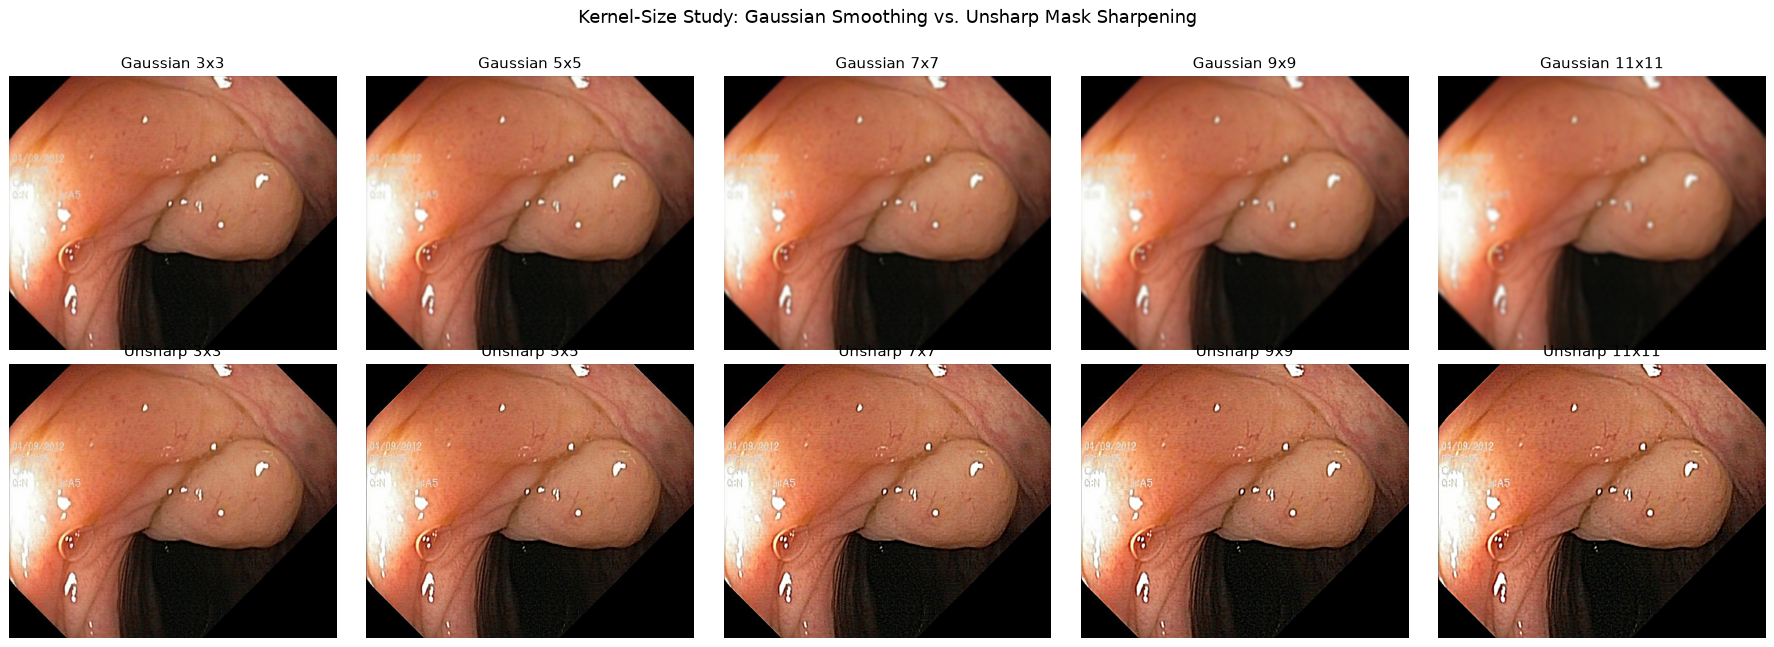

In [7]:
# ==========================================
# Cell 6: Kernel-Size Study (Required by Proposal)
# ==========================================

kernel_sizes = [3, 5, 7, 9, 11]
gauss_results = {}
unsharp_results = {}

for k in kernel_sizes:
    gauss_results[k] = apply_gaussian_smoothing(image, k=k, sigma=k / 3.0)
    unsharp_results[k] = apply_unsharp_mask(image, k=k, sigma=k / 3.0, amount=1.2)

fig, axes = plt.subplots(2, len(kernel_sizes), figsize=(20, 7))
for col, k in enumerate(kernel_sizes):
    axes[0, col].imshow(gauss_results[k])
    axes[0, col].set_title(f"Gaussian {k}x{k}")
    axes[0, col].axis("off")
    
    axes[1, col].imshow(unsharp_results[k])
    axes[1, col].set_title(f"Unsharp {k}x{k}")
    axes[1, col].axis("off")

plt.suptitle("Kernel-Size Study: Gaussian Smoothing vs. Unsharp Mask Sharpening", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Kernel-Size Study Quantitative Summary:")
print("-" * 45)
for k in kernel_sizes:
    g_std = np.std(gauss_results[k])
    u_std = np.std(unsharp_results[k])
    print(f"Kernel {k:2d}x{k:<2d} -> Gaussian Std: {g_std:5.2f} | Unsharp Std: {u_std:5.2f}")

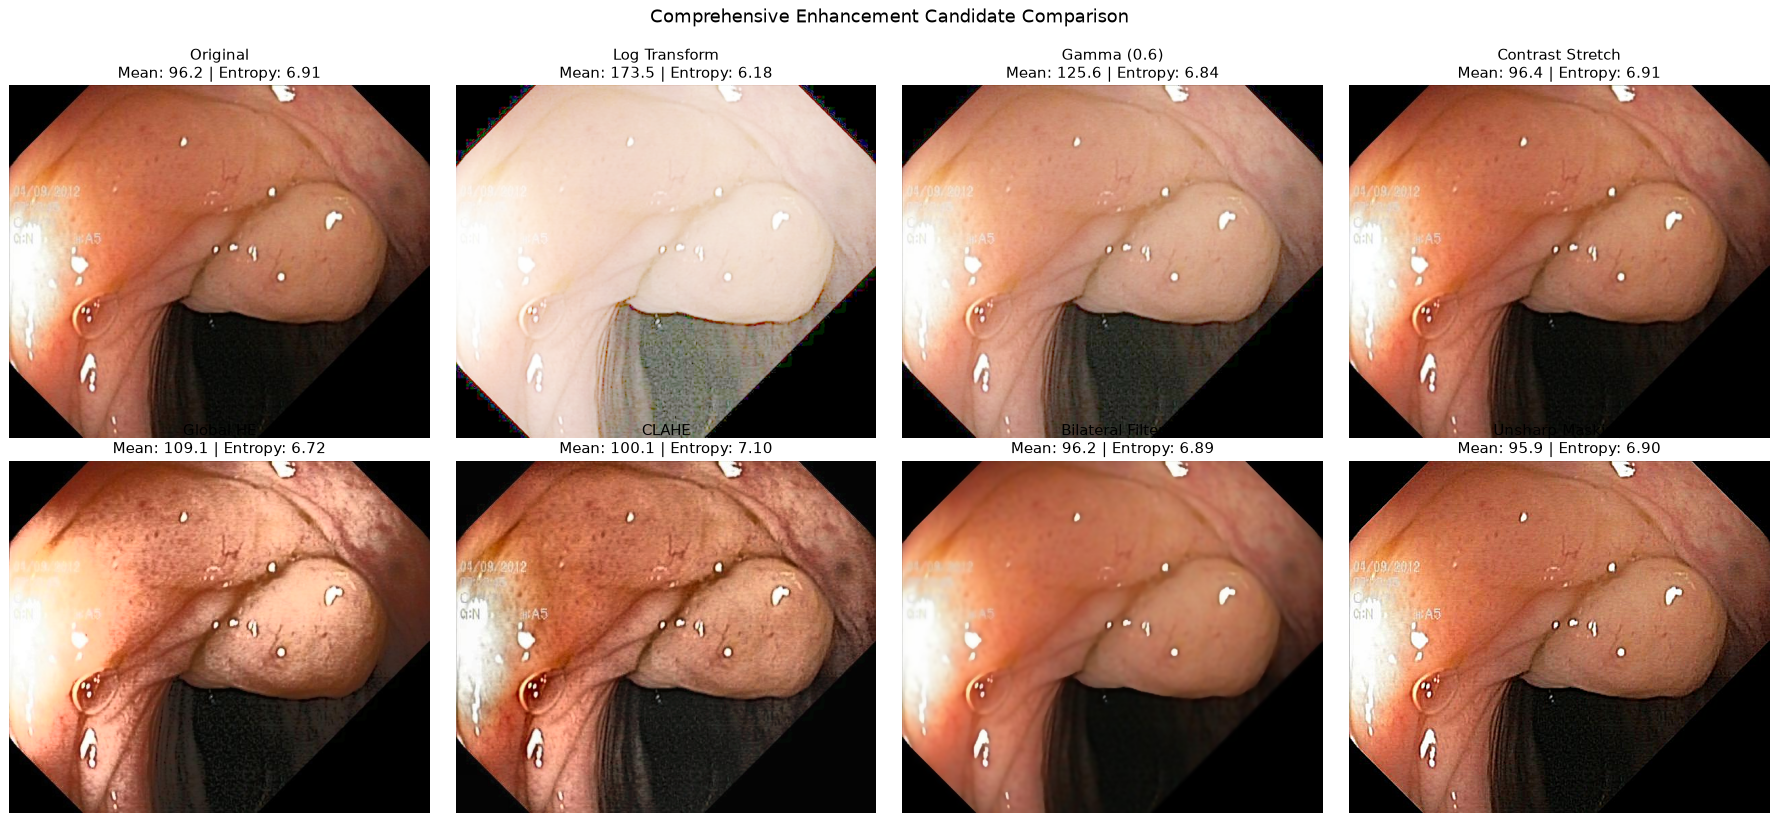

In [8]:
# ==========================================
# Cell 7: Enhancement Comparison Study (Required by Proposal)
# ==========================================

comparison = {
    "Original": image,
    "Log Transform": img_log,
    "Gamma (0.6)": img_gamma_low,
    "Contrast Stretch": img_contrast,
    "Global HE": he_img,
    "CLAHE": clahe_img,
    "Bilateral Filter": bilateral_img,
    "Unsharp Masking": unsharp_img
}

plt.figure(figsize=(20, 9))
for i, (name, img_c) in enumerate(comparison.items()):
    c_stats = analyze_histogram_stats(img_c)
    plt.subplot(2, 4, i + 1)
    plt.imshow(img_c)
    plt.title(f"{name}\nMean: {c_stats['mean']:.1f} | Entropy: {c_stats['entropy']:.2f}")
    plt.axis("off")

plt.suptitle("Comprehensive Enhancement Candidate Comparison", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 📋 Conclusions and Design Decisions for Polyp Pipeline

1. **CLAHE (Contrast Limited Adaptive Histogram Equalization)** is selected as the optimal contrast enhancer for endoscopic polyp images because it enhances the mucosal polyp boundaries without blowing out specular camera glare.
2. **Bilateral Filtering** is selected as the preferred smoothing filter because it reduces mucosal texture noise while preserving sharp polyp margins.
3. **Unsharp Masking (5x5 kernel)** provides the ideal boundary enhancement balance without over-amplifying noise.